In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/superstore.csv", encoding="latin-1")

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [3]:
chk = df.copy()

# --- Duplicates ---
print("Fully duplicated rows:", chk.duplicated().sum())
print("Row ID is unique:", chk["Row ID"].is_unique)
print("Duplicates ignoring Row ID:", chk.drop(columns="Row ID").duplicated().sum())

# --- Dates ---
chk["Order Date"] = pd.to_datetime(chk["Order Date"], format="%m/%d/%Y")
chk["Ship Date"] = pd.to_datetime(chk["Ship Date"], format="%m/%d/%Y")
print("Order date range:", chk["Order Date"].min(), "to", chk["Order Date"].max())
print("Shipped before ordered:", (chk["Ship Date"] < chk["Order Date"]).sum())

# --- Numeric validity ---
print("Sales <= 0:", (chk["Sales"] <= 0).sum())
print("Quantity <= 0:", (chk["Quantity"] <= 0).sum())
print("Discount outside 0-1:", ((chk["Discount"] < 0) | (chk["Discount"] > 1)).sum())
print("Negative profit rows:", (chk["Profit"] < 0).sum())
print(chk[["Sales", "Quantity", "Discount", "Profit"]].describe())

# --- Postal codes ---
print("Postal codes under 5 digits:", (chk["Postal Code"] < 10000).sum())

# --- Order consistency ---
print("Orders with more than one customer:",
      chk.groupby("Order ID")["Customer ID"].nunique().gt(1).sum())

# --- Text consistency ---
for col in ["Ship Mode", "Segment", "Country", "Region", "Category"]:
    print(col, "->", sorted(chk[col].unique()))

for col in chk.select_dtypes("object").columns:
    n = (chk[col] != chk[col].str.strip()).sum()
    if n > 0:
        print("Extra spaces in", col, ":", n)

Fully duplicated rows: 0
Row ID is unique: True
Duplicates ignoring Row ID: 1
Order date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00
Shipped before ordered: 0
Sales <= 0: 0
Quantity <= 0: 0
Discount outside 0-1: 0
Negative profit rows: 1871
              Sales     Quantity     Discount       Profit
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001     3.789574     0.156203    28.656896
std      623.245101     2.225110     0.206452   234.260108
min        0.444000     1.000000     0.000000 -6599.978000
25%       17.280000     2.000000     0.000000     1.728750
50%       54.490000     3.000000     0.200000     8.666500
75%      209.940000     5.000000     0.200000    29.364000
max    22638.480000    14.000000     0.800000  8399.976000
Postal codes under 5 digits: 449
Orders with more than one customer: 0
Ship Mode -> ['First Class', 'Same Day', 'Second Class', 'Standard Class']
Segment -> ['Consumer', 'Corporate', 'Home Office']
Country -> ['United Stat

In [4]:
# 1. The near-duplicate pair
cols = [c for c in df.columns if c != "Row ID"]
print(df[df.duplicated(subset=cols, keep=False)].T)

# 2. Which states have short postal codes?
short = df[df["Postal Code"] < 10000]
print(short["State"].value_counts())
print(short["Postal Code"].head().tolist())

# 3. Do losses relate to discount?
chk["Loss"] = chk["Profit"] < 0
print(chk.groupby("Discount")["Loss"].agg(["count", "mean"]))

# 4. Product Name examples with extra spaces
sp = df[df["Product Name"] != df["Product Name"].str.strip()]
print(sp["Product Name"].head().tolist())

# 5. Does one Product ID map to several names?
print("Product IDs with >1 name:",
      df.groupby("Product ID")["Product Name"].nunique().gt(1).sum())

                                                            3405  \
Row ID                                                      3406   
Order ID                                          US-2014-150119   
Order Date                                             4/23/2014   
Ship Date                                              4/27/2014   
Ship Mode                                         Standard Class   
Customer ID                                             LB-16795   
Customer Name                                     Laurel Beltran   
Segment                                              Home Office   
Country                                            United States   
City                                                    Columbus   
State                                                       Ohio   
Postal Code                                                43229   
Region                                                      East   
Product ID                                      

In [5]:
# A. Which states have short postal codes?
short = df[df["Postal Code"] < 10000]
print(short["State"].value_counts().to_string())

# B. Loss rate by discount level
chk["Loss"] = chk["Profit"] < 0
print(chk.groupby("Discount")["Loss"].agg(["count", "mean"]).to_string())

# C. Product IDs with conflicting names (after stripping spaces)
tmp = df.copy()
tmp["Product Name"] = tmp["Product Name"].str.strip()
multi = tmp.groupby("Product ID")["Product Name"].nunique()
print("Conflicts after strip():", (multi > 1).sum())

bad = tmp[tmp["Product ID"].isin(multi[multi > 1].index)]
print(bad.groupby(["Product ID", "Product Name"]).size().head(20).to_string())

State
Massachusetts    135
New Jersey       130
Connecticut       82
Rhode Island      56
New Hampshire     27
Vermont           11
Maine              8
          count      mean
Discount                 
0.00       4798  0.000000
0.10         94  0.042553
0.15         52  0.326923
0.20       3657  0.137271
0.30        227  0.916300
0.32         27  1.000000
0.40        206  0.873786
0.45         11  1.000000
0.50         66  1.000000
0.60        138  1.000000
0.70        418  1.000000
0.80        300  1.000000
Conflicts after strip(): 32
Product ID       Product Name                                                                           
FUR-BO-10002213  DMI Eclipse Executive Suite Bookcases                                                       6
                 Sauder Forest Hills Library, Woodland Oak Finish                                            4
FUR-CH-10001146  Global Task Chair, Black                                                                    5
                 

In [6]:
tmp = df.copy()
tmp["Product Name"] = tmp["Product Name"].str.strip()

# How many distinct (ID, name) combinations?
print("Distinct Product IDs:", tmp["Product ID"].nunique())
print("Distinct ID+Name pairs:", tmp[["Product ID", "Product Name"]].drop_duplicates().shape[0])

# Do category / sub-category also differ within a conflicting ID?
for col in ["Category", "Sub-Category"]:
    print(col, "conflicts per Product ID:",
          (tmp.groupby("Product ID")[col].nunique() > 1).sum())

# Customer and geography consistency (for the customers table design)
for col in ["Customer Name", "Segment"]:
    print(col, "conflicts per Customer ID:",
          (tmp.groupby("Customer ID")[col].nunique() > 1).sum())
print("Cities with >1 state:", (tmp.groupby(["City"])["State"].nunique() > 1).sum())
print("States with >1 region:", (tmp.groupby("State")["Region"].nunique() > 1).sum())

Distinct Product IDs: 1862
Distinct ID+Name pairs: 1894
Category conflicts per Product ID: 0
Sub-Category conflicts per Product ID: 0
Customer Name conflicts per Customer ID: 0
Segment conflicts per Customer ID: 0
Cities with >1 state: 57
States with >1 region: 0


In [7]:
import pandas as pd

c = pd.read_csv("../data/cleaned/superstore_clean.csv", dtype={"postal_code": str})

obj_cols = c.select_dtypes("object").columns
mask = c[obj_cols].apply(lambda s: s.str.contains(r"[^\x00-\x7F]")).any(axis=1)

# which columns contain them?
print(c[obj_cols].apply(lambda s: s.str.contains(r"[^\x00-\x7F]").sum()).loc[lambda s: s > 0])

# the distinct odd characters
chars = set("".join(c.loc[mask, obj_cols].astype(str).agg(" ".join, axis=1)))
print(sorted(ch for ch in chars if ord(ch) > 127))

# example values
print(c.loc[mask, "product_name"].drop_duplicates().head(8).tolist())

customer_name     89
product_name     278
dtype: int64
['\x93', '\x94', '\xa0', '¾', 'à', 'ä', 'é', 'ö', 'ü']
['Konftel 250 Conference\xa0phone\xa0- Charcoal black', 'Imation\xa08GB Mini TravelDrive USB 2.0\xa0Flash Drive', 'Imation\xa08gb Micro Traveldrive Usb 2.0\xa0Flash Drive', 'Logitech\xa0LS21 Speaker System - PC Multimedia - 2.1-CH - Wired', 'Logitech\xa0Gaming G510s - Keyboard', 'Plantronics Cordless\xa0Phone Headset\xa0with In-line Volume - M214C', 'Jabra BIZ 2300 Duo QD Duo Corded\xa0Headset', 'Adams Phone Message Book, Professional, 400 Message Capacity, 5 3/6\x94 x 11\x94']


          sales    profit  margin_pct
year                                 
2014  483966.13  49556.03        10.2
2015  470532.51  61618.60        13.1
2016  609205.60  81795.17        13.4
2017  733215.26  93439.27        12.7
                     sales     profit  margin_pct
category                                         
Furniture        741718.42   18463.33         2.5
Office Supplies  719047.03  122490.80        17.0
Technology       836154.03  145454.95        17.4
sub_category
Tables        -17725.48
Bookcases      -3472.56
Supplies       -1189.10
Fasteners        949.52
Machines        3384.76
Labels          5546.25
Art             6527.79
Envelopes       6964.18
Furnishings    13059.14
Appliances     18138.01
Storage        21278.83
Chairs         26602.23
Binders        30221.76
Paper          34053.57
Accessories    41936.64
Phones         44515.73
Copiers        55617.82
             sales     profit
region                       
Central  501239.89   39706.36
East     67

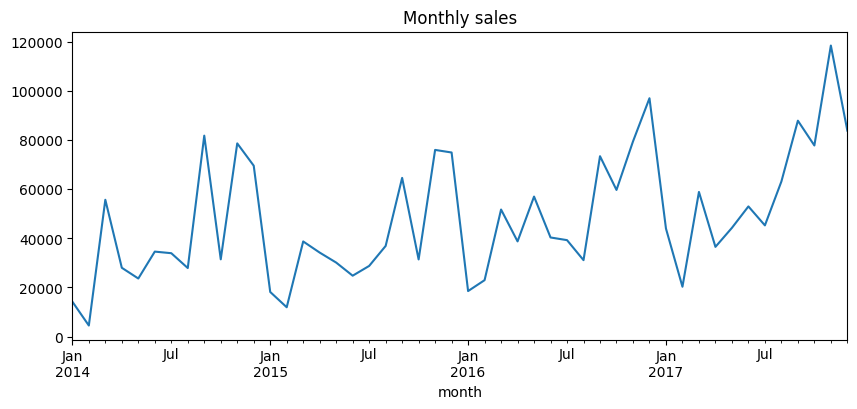

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/cleaned/superstore_clean.csv",
                 dtype={"postal_code": str},
                 parse_dates=["order_date", "ship_date"])

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.to_period("M")

# 1. Yearly sales and profit
yearly = df.groupby("year")[["sales", "profit"]].sum().round(2)
yearly["margin_pct"] = (yearly["profit"] / yearly["sales"] * 100).round(1)
print(yearly)

# 2. Category and sub-category profitability
cat = df.groupby("category")[["sales", "profit"]].sum().round(2)
cat["margin_pct"] = (cat["profit"] / cat["sales"] * 100).round(1)
print(cat)
print(df.groupby("sub_category")["profit"].sum().sort_values().round(2).to_string())

# 3. Region
reg = df.groupby("region")[["sales", "profit"]].sum().round(2)
print(reg)

# 4. Monthly trend chart
monthly = df.groupby("month")["sales"].sum()
monthly.plot(figsize=(10, 4), title="Monthly sales")
plt.show()

In [9]:
c = pd.read_csv("../data/cleaned/superstore_clean.csv", dtype={"postal_code": str})
for col in ["order_date", "ship_date", "ship_mode", "city", "state", "postal_code", "region"]:
    print(col, "-> orders with >1 value:", (c.groupby("order_id")[col].nunique() > 1).sum())

order_date -> orders with >1 value: 0
ship_date -> orders with >1 value: 0
ship_mode -> orders with >1 value: 0
city -> orders with >1 value: 0
state -> orders with >1 value: 0
postal_code -> orders with >1 value: 0
region -> orders with >1 value: 0
